# Measurment of thermocouple voltage during melting of tin

Import the serial library, scan for port to identify the serial com, define the com address

In [1]:
import serial
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
import serial.tools.list_ports as port_list
ports = list(port_list.comports())
for p in ports: print(p)

COM1 - Port de communication (COM1)
COM8 - USB Serial Port (COM8)


In [3]:
serial_add = 'COM8'
ser = serial.Serial(serial_add,baudrate=9600,bytesize=8, parity='N',stopbits=1,timeout=.5)

## Preliminary work to test the serial communication with the Keithley2000

Ask for the instrument ID, set the insturment to Volt DC, ask that the instrument to check if it is correctly configured in this mode configured, set the integration time to 5, the range to mV <br>
Retrieve one data

In [4]:
ser.write(b'*IDN?\r')
l=ser.readline()
response=l.decode('ascii', errors='replace')
print(response)

KEITHLEY INSTRUMENTS INC.,MODEL 2000,4042349,B01  /A02  


In [5]:
ser.write(b"CONF:VOLT:DC 0 \n")

16

In [6]:
ser.write(b"FUNC?\n")
print(ser.readline().decode().strip())

"VOLT:DC"


In [7]:
ser.write(b"VOLT:DC:NPLC 1\n")

15

In [114]:
ser.write(b"READ?\n")

6

Nous mesurons $2.77e^{-3}$ mV

Transform the data to a float number

In [52]:
print(float(ser.readline().decode())*1e3)

0.00277318964


---

Prepare for the measurments, you will need to retrieve data every 1s and store both time and voltage and temperature in arrays during at least 900s. Convert the data to temperature using the polynomial equation for a K-type thermocouple from https://aviatechno.net/thermo/table_its90.php?type=K

In [8]:
dt = 1
NPLC = dt/0.2
print(NPLC)

5.0


In [20]:
def aquis(dt,N):
    tab = np.zeros(N)
    t = np.arange(N)*dt
    
    for i in range(N):
        ser.write(b"READ?\n")
        start = time.time()
        tab[i] = float(ser.readline().decode())*1e3
        while time.time() - start < dt:
            pass
    return tab, t

In [13]:
Data = aquis(1,300)

In [12]:
len(Data[0])

30

In [23]:
coefs = np.array([-1.05e-8,1.05e-6,-4.41e-5,9.80e-4,-1.22e-2,8.31e-2,-2.50e-1,7.86e-2,2.51e1,0])
T = np.polyval(coefs,Data[0]*1e3)
t = Data[1]

You may use the following librairies to acquire and plot the data. Save them to a file.

from numpy import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from time import sleep

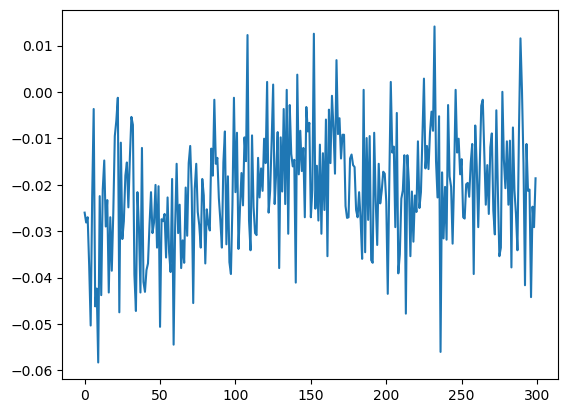

In [24]:
plt.plot(t,T)